# 1. Реализуйте высокочастотную фильтрацию на основе ядра Гаусса

In [1]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

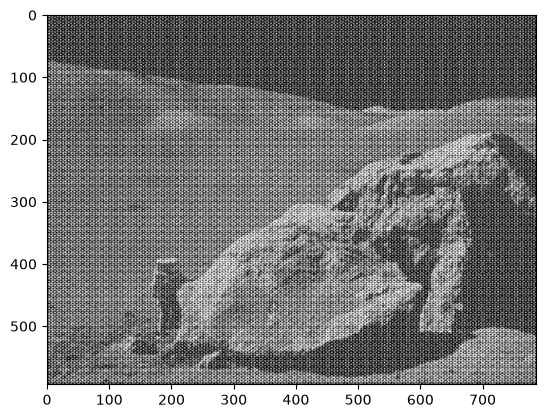

In [4]:
img = cv.imread('periodic_noise.JPG', cv.IMREAD_GRAYSCALE)
plt.imshow(image, cmap='gray')

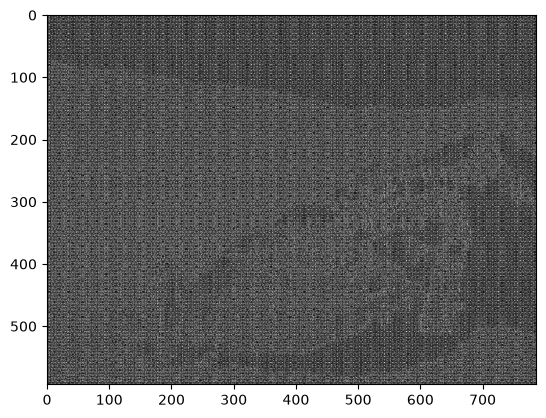

In [6]:

dft = cv.dft(np.float32(img), flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

rows, cols = img.shape
crow, ccol = int(rows/2), int(cols/2)
X, Y = np.meshgrid(np.arange(cols) - ccol, np.arange(rows) - crow)
D = np.sqrt(X**2 + Y**2)

mask = 1 - np.exp(-(D**2) / (2 * (30**2)))
mask = np.dstack([mask, mask])

dft_shift = dft_shift * mask
f_ishift = np.fft.ifftshift(dft_shift)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:,:,0], img_back[:,:,1])

plt.imshow(img_back, cmap = 'gray')

# 2. Реализуйте вычисление свёртки (любой из изученных) с помощью преобразования Фурье

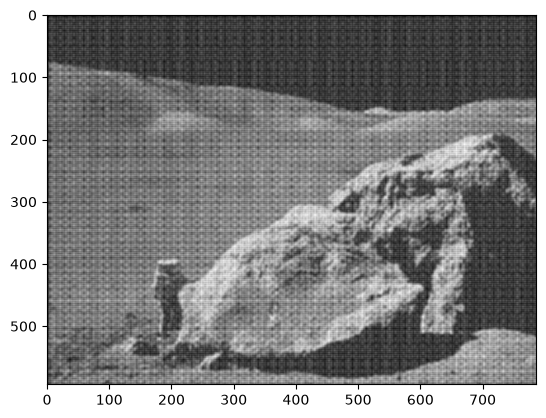

In [11]:
# ядро — усредняющий фильтр 5x5 (2D-свёртка)
kernel = np.ones((5,5), np.float32) / 25

kernel_padded = np.zeros_like(img, dtype=np.float32)
kernel_padded[:5, :5] = kernel

dft_img = np.fft.fft2(img)
dft_kernel = np.fft.fft2(kernel_padded)

dft_result = dft_img * dft_kernel

img_back = np.abs(np.fft.ifft2(dft_result))

plt.imshow(img_back, cmap = 'gray')

# 3. Реализуйте удаление периодического шума с помощью преобразования Фурье

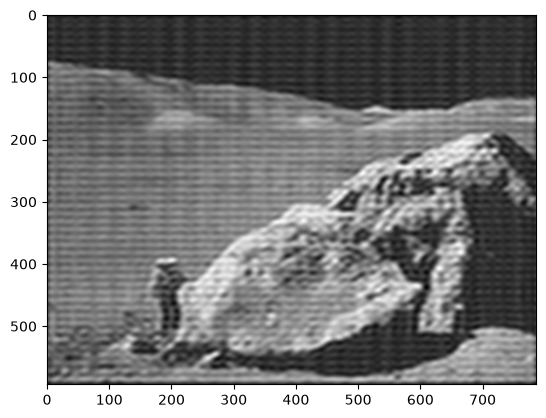

In [13]:
dft = cv.dft(np.float32(img), flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

mask = np.zeros((img.shape[0],img.shape[1],2),np.uint8)
centerX, centerY = (int(img.shape[0] / 2),int(img.shape[1] / 2))
mask[centerX-50:centerX+50, centerY-50:centerY+50,:] = 1

dft_shift = dft_shift*mask

f_ishift = np.fft.ifftshift(dft_shift)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:,:,0],img_back[:,:,1])

plt.imshow(img_back, cmap = 'gray')